# Supplementary Figure S1 — plotting

Reads only outputs from the paired analysis notebook.


In [8]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path(os.environ.get("MITOXY_PROJECT_ROOT","/scratch/ar58064/mitoxy")).resolve()
BLUE="#087EBD"; ORANGE="#E36A00"; TEAL="#00A67E"; PURPLE="#8053A6"
DARK="#202832"; MID="#667386"; GRID="#DDE3E9"; BAND="#F2F5F8"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelcolor":DARK,
 "xtick.color":MID,"ytick.color":DARK,"axes.edgecolor":"#AEB8C4","axes.spines.top":False,
 "axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})

def panel_letter(ax,letter):
    ax.text(-.14,1.08,letter,transform=ax.transAxes,fontsize=21,fontweight="bold",color=DARK,va="top")

def band_rows(ax,n):
    for i in range(n):
        if i%2==0: ax.axhspan(i-.5,i+.5,color=BAND,zorder=0)

def p_text(p): return "P < 1e-4" if p < 1e-4 else f"P = {p:.3f}"

def stat_box(ax,y,text,color,x=.79):
    # Anchor the box to its data row while keeping a fixed right-side x position.
    ax.text(x,y,text,transform=ax.get_yaxis_transform(),ha="left",va="center",fontsize=8.3,fontweight="bold",color=color,
            bbox=dict(boxstyle="round,pad=.26",facecolor="white",edgecolor=color,alpha=.95,linewidth=1))

def reserve_stat_space(ax,fraction=.32):
    # Add a dedicated annotation lane to the right of every confidence interval.
    left,right=ax.get_xlim(); span=right-left
    ax.set_xlim(left,right+span*fraction)

def save_all(fig,stem,folder):
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ["png","pdf","svg"]:
        fig.savefig(folder/f"{stem}.{ext}",dpi=320 if ext=="png" else None,bbox_inches="tight")

DATA_DIR=PROJECT_ROOT/"data"/"processed"/"supplementary_figure_s1"
FIGURE_DIR=PROJECT_ROOT/"figures"/"supplementary_figure_s1"
a=pd.read_csv(DATA_DIR/"panel_a_tracerx_clinical.csv"); b=pd.read_csv(DATA_DIR/"panel_b_emtab_adjusted.csv")
c=pd.read_csv(DATA_DIR/"panel_c_emtab_survival.csv"); d=pd.read_csv(DATA_DIR/"panel_d_tcga_survival.csv")



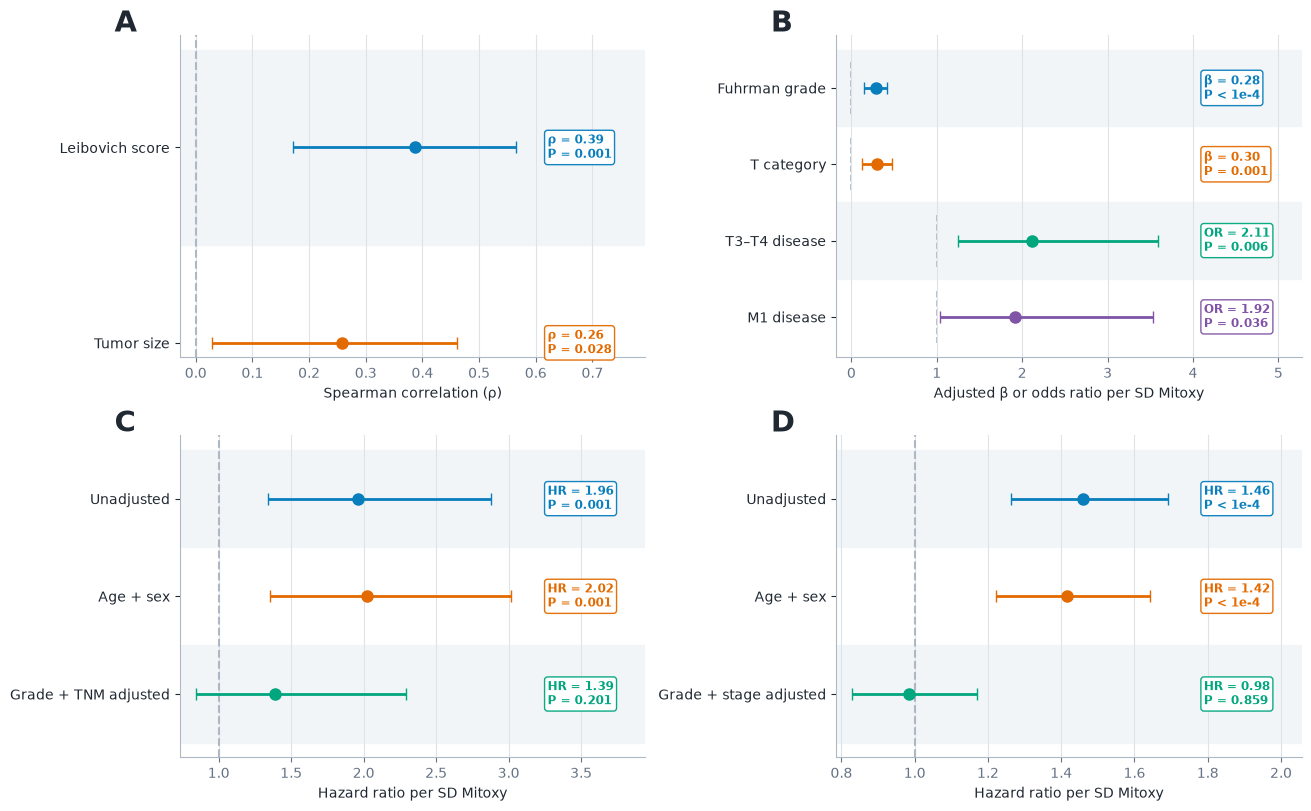

In [10]:
fig,axes=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)

# A: correlations, with the correlation null at zero.
ax=axes[0,0]; table=a.reset_index(drop=True); y=np.arange(len(table)); band_rows(ax,len(table)); ax.axvline(0,color="#AEB8C4",ls="--")
for i,row in table.iterrows():
    color=[BLUE,ORANGE][i%2]
    ax.errorbar(row.rho,i,xerr=[[row.rho-row.ci_low],[row.ci_high-row.rho]],fmt="o",ms=8,color=color,capsize=4,lw=2,zorder=3)
reserve_stat_space(ax)
for i,row in table.iterrows():
    color=[BLUE,ORANGE][i%2]
    stat_box(ax,i,f"ρ = {row.rho:.2f}\n{p_text(row.p_value)}",color)
ax.set_yticks(y,table.endpoint); ax.invert_yaxis(); ax.set_xlabel("Spearman correlation (ρ)"); ax.grid(axis="x",color=GRID)
ax.set_title("",loc="left",fontweight="bold",color=DARK); panel_letter(ax,"A")

# B: beta coefficients and odds ratios share a panel but have different nulls.
ax=axes[0,1]; table=b.reset_index(drop=True); y=np.arange(len(table)); band_rows(ax,len(table))
for i,row in table.iterrows():
    color=[BLUE,ORANGE,TEAL,PURPLE][i%4]
    null=0 if row.effect_type=="beta" else 1
    ax.plot([null,null],[i-.34,i+.34],color="#AEB8C4",ls="--",lw=1.25,zorder=1)
    ax.errorbar(row.effect,i,xerr=[[row.effect-row.ci_low],[row.ci_high-row.effect]],fmt="o",ms=8,color=color,capsize=4,lw=2,zorder=3)
reserve_stat_space(ax,.38)
for i,row in table.iterrows():
    color=[BLUE,ORANGE,TEAL,PURPLE][i%4]
    symbol="β" if row.effect_type=="beta" else "OR"
    stat_box(ax,i,f"{symbol} = {row.effect:.2f}\n{p_text(row.p_value)}",color)
ax.set_yticks(y,table.endpoint); ax.invert_yaxis(); ax.set_xlabel("Adjusted β or odds ratio per SD Mitoxy"); ax.grid(axis="x",color=GRID)
ax.set_title("",loc="left",fontweight="bold",color=DARK); panel_letter(ax,"B")

# C/D: hazard ratios, with the survival null at one.
for ax,table,title,letter in [(axes[1,0],c,"","C"),(axes[1,1],d,"","D")]:
    table=table.reset_index(drop=True); y=np.arange(len(table)); band_rows(ax,len(table)); ax.axvline(1,color="#AEB8C4",ls="--")
    for i,row in table.iterrows():
        color=[BLUE,ORANGE,TEAL][i%3]
        ax.errorbar(row.effect,i,xerr=[[row.effect-row.ci_low],[row.ci_high-row.effect]],fmt="o",ms=8,color=color,capsize=4,lw=2,zorder=3)
    reserve_stat_space(ax,.34)
    for i,row in table.iterrows():
        color=[BLUE,ORANGE,TEAL][i%3]
        stat_box(ax,i,f"HR = {row.effect:.2f}\n{p_text(row.p_value)}",color)
    ax.set_yticks(y,table.model); ax.invert_yaxis(); ax.set_xlabel("Hazard ratio per SD Mitoxy"); ax.grid(axis="x",color=GRID)
    ax.set_title(title,loc="left",fontweight="bold",color=DARK); panel_letter(ax,letter)

save_all(fig,"Supplementary_Figure_S1",FIGURE_DIR); plt.show()

